# CardioFlow ECG AI - PTB-XL en moins de deux heures

Ce notebook construit un vrai prototype d'IA : classification **multilabel** de cinq superclasses ECG (`NORM`, `MI`, `STTC`, `CD`, `HYP`) avec un CNN 1D. Il utilise les folds patients officiels PTB-XL, mesure AUROC/AUPRC/F1 et ajoute une carte de saillance.

> **Avertissement :** projet pedagogique et de recherche. Ce modele n'est pas valide cliniquement et ne doit jamais guider un diagnostic ou un traitement.

Avant de commencer : **Runtime > Change runtime type > T4 GPU**. Execute ensuite chaque cellule dans l'ordre et lis les commentaires : le but est de comprendre le pipeline, pas seulement d'obtenir un score.

## 1. Installer et verifier l'environnement

Colab fournit deja TensorFlow. Nous ajoutons WFDB pour lire les signaux PhysioNet et Gradio pour la demo.

In [1]:
%pip install -q "wfdb>=4.1,<5" "gradio>=5,<7"

import ast
import json
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
import wfdb
from sklearn.metrics import (
    average_precision_score, f1_score, roc_auc_score
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow :', tf.__version__)
print('GPU detecte :', tf.config.list_physical_devices('GPU'))


TensorFlow : 2.21.0
GPU detecte : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configurer une experience courte

Les valeurs ci-dessous donnent un prototype rapide. Quand tout fonctionne, augmente progressivement les tailles au lieu de modifier plusieurs parametres en meme temps.

In [2]:
PTBXL_BASE_URL = 'https://physionet.org/files/ptb-xl/1.0.3/'
DATA_DIR = Path('/content/ptbxl_subset')
DATA_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_SAMPLES = 1200
VAL_SAMPLES = 200
TEST_SAMPLES = 200
EPOCHS = 6
BATCH_SIZE = 64
MAX_DOWNLOAD_WORKERS = 8

CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
print('Classes cibles :', CLASSES)


Classes cibles : ['NORM', 'MI', 'STTC', 'CD', 'HYP']


## 3. Charger les annotations et construire les cinq labels

Un ECG peut posseder plusieurs diagnostics : la cible est donc un vecteur de cinq valeurs binaires et non une classe unique.

In [3]:
metadata_url = PTBXL_BASE_URL + 'ptbxl_database.csv'
statements_url = PTBXL_BASE_URL + 'scp_statements.csv'

metadata = pd.read_csv(metadata_url, index_col='ecg_id')
statements = pd.read_csv(statements_url, index_col=0)
diagnostic_map = (
    statements.loc[statements['diagnostic'] == 1, 'diagnostic_class']
    .dropna()
    .to_dict()
)

def aggregate_superclasses(raw_codes):
    """Convertit le dictionnaire SCP-ECG d'un enregistrement en superclasses."""
    codes = ast.literal_eval(raw_codes) if isinstance(raw_codes, str) else raw_codes
    return sorted({diagnostic_map[code] for code in codes if code in diagnostic_map})

metadata['labels'] = metadata['scp_codes'].apply(aggregate_superclasses)
metadata = metadata[metadata['labels'].map(len) > 0].copy()

def multilabel_vector(labels):
    return np.array([int(name in labels) for name in CLASSES], dtype=np.float32)

metadata['target'] = metadata['labels'].apply(multilabel_vector)
print('ECG diagnostiques disponibles :', len(metadata))
display(metadata[['patient_id', 'strat_fold', 'filename_lr', 'labels']].head())


ECG diagnostiques disponibles : 21388


,patient_id,strat_fold,filename_lr,labels
ecg_id,,,,
1,15709.0,3,records100/00000/00001_lr,[NORM]
2,13243.0,2,records100/00000/00002_lr,[NORM]
3,20372.0,5,records100/00000/00003_lr,[NORM]
4,17014.0,3,records100/00000/00004_lr,[NORM]
5,17448.0,4,records100/00000/00005_lr,[NORM]


## 4. Respecter les folds patients et choisir le sous-ensemble

PTB-XL recommande les folds 1-8 pour l'entrainement, 9 pour la validation et 10 pour le test. Cette regle evite une fuite d'information entre les ECG d'un meme patient.

In [4]:
def sample_rows(frame, count, seed):
    return frame.sample(n=min(count, len(frame)), random_state=seed).copy()

train_df = sample_rows(metadata[metadata['strat_fold'] <= 8], TRAIN_SAMPLES, SEED)
val_df = sample_rows(metadata[metadata['strat_fold'] == 9], VAL_SAMPLES, SEED + 1)
test_df = sample_rows(metadata[metadata['strat_fold'] == 10], TEST_SAMPLES, SEED + 2)

assert set(train_df['patient_id']).isdisjoint(set(val_df['patient_id']))
assert set(train_df['patient_id']).isdisjoint(set(test_df['patient_id']))
assert set(val_df['patient_id']).isdisjoint(set(test_df['patient_id']))

def label_prevalence(frame):
    matrix = np.stack(frame['target'].to_numpy())
    return pd.Series(matrix.mean(axis=0), index=CLASSES, name='prevalence')

print('Tailles :', len(train_df), len(val_df), len(test_df))
display(pd.concat({
    'train': label_prevalence(train_df),
    'validation': label_prevalence(val_df),
    'test': label_prevalence(test_df),
}, axis=1).round(3))


Tailles : 1200 200 200


,train,validation,test
NORM,0.438,0.460,0.500
MI,0.251,0.215,0.275
STTC,0.269,0.235,0.205
CD,0.211,0.240,0.230
HYP,0.132,0.140,0.110


## 5. Telecharger seulement les signaux selectionnes

Chaque ECG 100 Hz contient 1 000 instants et 12 derivations. Le telechargement concurrent evite de recuperer les 3 Go du dataset complet.

In [5]:
def download_file(url, destination, retries=3):
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        return destination
    for attempt in range(retries):
        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            destination.write_bytes(response.content)
            return destination
        except requests.RequestException:
            if attempt == retries - 1:
                raise
            time.sleep(2 ** attempt)

def download_record(relative_base):
    for suffix in ('.hea', '.dat'):
        relative_file = relative_base + suffix
        download_file(PTBXL_BASE_URL + relative_file, DATA_DIR / relative_file)
    return relative_base

all_paths = pd.concat([train_df, val_df, test_df])['filename_lr'].drop_duplicates().tolist()
with ThreadPoolExecutor(max_workers=MAX_DOWNLOAD_WORKERS) as executor:
    futures = [executor.submit(download_record, path) for path in all_paths]
    for future in tqdm(as_completed(futures), total=len(futures), desc='ECG telecharges'):
        future.result()

print('Telechargement termine :', len(all_paths), 'ECG')


ECG telecharges:   0%|          | 0/1600 [00:00<?, ?it/s]

Telechargement termine : 1600 ECG


## 6. Construire les tenseurs et normaliser chaque derivation

La normalisation est calculee a l'interieur de chaque ECG et de chaque derivation. Elle limite les differences d'amplitude sans utiliser d'information du test pendant l'entrainement.

In [6]:
def load_split(frame):
    signals, targets = [], []
    for _, row in tqdm(frame.iterrows(), total=len(frame), desc='Lecture WFDB'):
        record = wfdb.rdrecord(str(DATA_DIR / row['filename_lr']))
        signal = np.asarray(record.p_signal, dtype=np.float32)
        if signal.shape != (1000, 12):
            raise ValueError(f"Forme ECG inattendue : {signal.shape}")
        signal = np.nan_to_num(signal)
        mean = signal.mean(axis=0, keepdims=True)
        std = signal.std(axis=0, keepdims=True) + 1e-6
        signals.append((signal - mean) / std)
        targets.append(row['target'])
    return np.stack(signals), np.stack(targets)

X_train, y_train = load_split(train_df)
X_val, y_val = load_split(val_df)
X_test, y_test = load_split(test_df)

print('Train :', X_train.shape, y_train.shape)
print('Validation :', X_val.shape, y_val.shape)
print('Test :', X_test.shape, y_test.shape)
assert X_train.shape[1:] == (1000, 12)


Lecture WFDB:   0%|          | 0/1200 [00:00<?, ?it/s]

Lecture WFDB:   0%|          | 0/200 [00:00<?, ?it/s]

Lecture WFDB:   0%|          | 0/200 [00:00<?, ?it/s]

Train : (1200, 1000, 12) (1200, 5)
Validation : (200, 1000, 12) (200, 5)
Test : (200, 1000, 12) (200, 5)


## 7. Construire et entrainer le CNN 1D

Les convolutions parcourent le temps tout en utilisant simultanement les douze derivations comme canaux. La sortie sigmoid contient cinq probabilites independantes.

In [7]:
def build_model():
    inputs = tf.keras.Input(shape=(1000, 12), name='ecg')
    x = inputs
    for filters, kernel in [(32, 9), (64, 7), (128, 5)]:
        x = tf.keras.layers.Conv1D(filters, kernel, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPool1D(2)(x)
    x = tf.keras.layers.Conv1D(128, 3, padding='same', activation='relu', name='last_conv')(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(len(CLASSES), activation='sigmoid', name='diagnosis')(x)
    model = tf.keras.Model(inputs, outputs, name='cardioflow_cnn1d')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(curve='ROC', multi_label=True, name='auc')],
    )
    return model

model = build_model()
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=2, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5
    ),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)


Model: "cardioflow_cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ecg (InputLayer)                │ (None, 1000, 12)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1000, 32)       │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1000, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 64)        │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 250, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 128)       │        40,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 250, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 125, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv1D)              │ (None, 125, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ diagnosis (Dense)               │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,573 (428.02 KB)

 Trainable params: 109,125 (426.27 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 29s 796ms/step - auc: 0.6135 - loss: 0.5515 - val_auc: 0.8035 - val_loss: 0.5385 - learning_rate: 0.0010
Epoch 2/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc: 0.7866 - loss: 0.4298 - val_auc: 0.8349 - val_loss: 0.4725 - learning_rate: 0.0010
Epoch 3/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc: 0.8320 - loss: 0.3879 - val_auc: 0.8517 - val_loss: 0.4272 - learning_rate: 0.0010
Epoch 4/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc: 0.8535 - loss: 0.3634 - val_auc: 0.8632 - val_loss: 0.4049 - learning_rate: 0.0010
Epoch 5/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc: 0.8649 - loss: 0.3483 - val_auc: 0.8683 - val_loss: 0.3980 - learning_rate: 0.0010
Epoch 6/6
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - auc: 0.8827 - loss: 0.3263 - val_auc: 0.8733 - val_loss: 0.3841 - learning_rate: 0.0010


## 8. Calibrer les seuils et evaluer une seule fois sur le test

Le seuil 0,5 n'est pas automatiquement optimal, surtout avec des classes desequilibrees. Chaque seuil est choisi sur la validation, puis gele avant le test.

,seuil,AUROC,AUPRC,F1,support
classe,,,,,
NORM,0.40,0.929,0.931,0.844,100
MI,0.25,0.878,0.712,0.680,55
STTC,0.35,0.906,0.726,0.675,41
CD,0.60,0.808,0.645,0.628,46
HYP,0.35,0.829,0.523,0.473,22


{'macro_auroc': 0.87, 'macro_auprc': 0.707, 'macro_f1': 0.66}


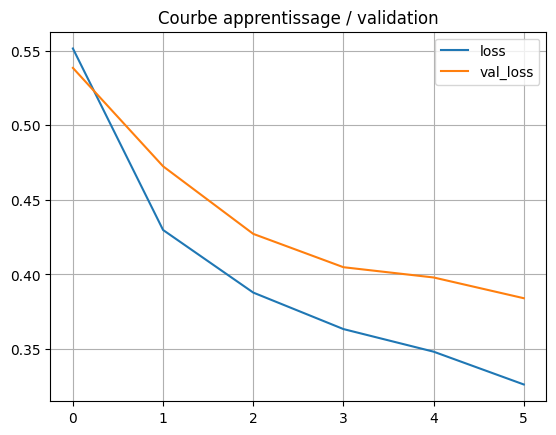

In [8]:
val_probabilities = model.predict(X_val, verbose=0)
test_probabilities = model.predict(X_test, verbose=0)

def tune_thresholds(y_true, probabilities):
    thresholds = []
    grid = np.arange(0.10, 0.91, 0.05)
    for class_index in range(len(CLASSES)):
        scores = [
            f1_score(
                y_true[:, class_index],
                probabilities[:, class_index] >= threshold,
                zero_division=0,
            )
            for threshold in grid
        ]
        thresholds.append(float(grid[int(np.argmax(scores))]))
    return np.array(thresholds, dtype=np.float32)

thresholds = tune_thresholds(y_val, val_probabilities)
test_predictions = (test_probabilities >= thresholds).astype(int)

rows = []
for index, class_name in enumerate(CLASSES):
    rows.append({
        'classe': class_name,
        'seuil': thresholds[index],
        'AUROC': roc_auc_score(y_test[:, index], test_probabilities[:, index]),
        'AUPRC': average_precision_score(y_test[:, index], test_probabilities[:, index]),
        'F1': f1_score(y_test[:, index], test_predictions[:, index], zero_division=0),
        'support': int(y_test[:, index].sum()),
    })

metrics_table = pd.DataFrame(rows).set_index('classe')
macro_metrics = {
    'macro_auroc': float(roc_auc_score(y_test, test_probabilities, average='macro')),
    'macro_auprc': float(average_precision_score(y_test, test_probabilities, average='macro')),
    'macro_f1': float(f1_score(y_test, test_predictions, average='macro', zero_division=0)),
}
display(metrics_table.round(3))
print({name: round(value, 3) for name, value in macro_metrics.items()})

history_frame = pd.DataFrame(history.history)
history_frame[['loss', 'val_loss']].plot(title='Courbe apprentissage / validation', grid=True)
plt.show()


## 9. Expliquer une prediction avec une carte de saillance

La saillance mesure la sensibilite locale de la probabilite aux echantillons. Elle aide a inspecter le modele, mais ne constitue pas une justification clinique causale.

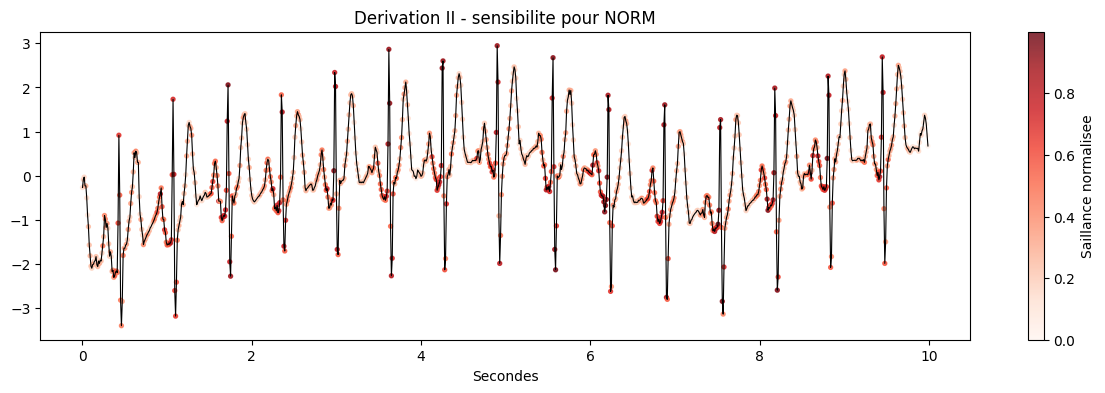

In [9]:
def temporal_saliency(trained_model, signal, class_index):
    tensor = tf.convert_to_tensor(signal[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(tensor)
        score = trained_model(tensor, training=False)[0, class_index]
    gradients = tape.gradient(score, tensor)[0].numpy()
    saliency = np.abs(gradients).mean(axis=1)
    saliency = (saliency - saliency.min()) / (np.ptp(saliency) + 1e-8)
    return saliency

example_index = 0
predicted_class = int(np.argmax(test_probabilities[example_index]))
saliency = temporal_saliency(model, X_test[example_index], predicted_class)
seconds = np.arange(1000) / 100.0
lead_index = LEADS.index('II')

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(seconds, X_test[example_index, :, lead_index], color='black', linewidth=0.8)
points = ax.scatter(
    seconds, X_test[example_index, :, lead_index],
    c=saliency, cmap='Reds', s=8, alpha=0.8
)
ax.set(title=f"Derivation II - sensibilite pour {CLASSES[predicted_class]}", xlabel='Secondes')
fig.colorbar(points, ax=ax, label='Saillance normalisee')
plt.show()


## 10. Lancer une mini-demo Gradio

La demo permet de parcourir cinquante ECG du test, de comparer probabilites et annotations, et d'afficher les douze derivations.

In [10]:
def build_demo_result(record_number):
    index = int(record_number)
    signal = X_test[index]
    probabilities = test_probabilities[index]

    fig, axes = plt.subplots(6, 2, figsize=(14, 12), sharex=True)
    seconds = np.arange(signal.shape[0]) / 100.0
    for lead_index, axis in enumerate(axes.flat):
        axis.plot(seconds, signal[:, lead_index], linewidth=0.65)
        axis.set_title(LEADS[lead_index], loc='left', fontsize=9)
        axis.grid(alpha=0.2)
    axes[-1, 0].set_xlabel('Secondes')
    axes[-1, 1].set_xlabel('Secondes')
    fig.suptitle('ECG PTB-XL normalise - donnees de test')
    fig.tight_layout()

    result = pd.DataFrame({
        'classe': CLASSES,
        'probabilite': np.round(probabilities, 3),
        'seuil': np.round(thresholds, 2),
        'prediction': probabilities >= thresholds,
        'annotation_reference': y_test[index].astype(bool),
    })
    return fig, result

demo = gr.Interface(
    fn=build_demo_result,
    inputs=gr.Slider(0, min(49, len(X_test) - 1), value=0, step=1, label='Index ECG test'),
    outputs=[gr.Plot(label='ECG 12 derivations'), gr.Dataframe(label='Resultats')],
    title='CardioFlow ECG AI',
    description='Prototype de recherche - aucune utilisation clinique.',
)
demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b176ac785e91c7eb7a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Sauvegarder les livrables

Telecharge ces trois fichiers avant de fermer Colab. Ne versionne pas les poids du modele dans GitHub s'ils deviennent volumineux ; utilise plutot une GitHub Release.

In [11]:
model.save('/content/cardioflow_cnn.keras')

metrics_payload = {
    'dataset': 'PTB-XL 1.0.3 subset',
    'seed': SEED,
    'samples': {
        'train': len(X_train), 'validation': len(X_val), 'test': len(X_test)
    },
    **macro_metrics,
    'per_class': metrics_table.reset_index().to_dict(orient='records'),
}
with open('/content/metrics.json', 'w', encoding='utf-8') as handle:
    json.dump(metrics_payload, handle, indent=2, default=float)
with open('/content/thresholds.json', 'w', encoding='utf-8') as handle:
    json.dump(dict(zip(CLASSES, map(float, thresholds))), handle, indent=2)

print('Fichiers crees :')
print('/content/cardioflow_cnn.keras')
print('/content/metrics.json')
print('/content/thresholds.json')
print('Dans Colab : panneau Files > clic droit > Download')


Fichiers crees :
/content/cardioflow_cnn.keras
/content/metrics.json
/content/thresholds.json
Dans Colab : panneau Files > clic droit > Download


## Conclusion a presenter

Le prototype demontre une chaine complete et reproductible : donnees ECG reelles, prevention de la fuite patient, CNN multilabel, calibration, evaluation separee, explicabilite et interface de demonstration. La limite principale est l'entrainement sur un sous-ensemble : les scores illustrent une methode d'ingenierie, pas une performance clinique.